In [21]:
import pandas as pd

# ==========================================
# VERİ TOPLAMA VE HAZIRLIK
# ==========================================

# 1. Ham veri setlerimizi (frekans özellikleri ve şarkı metadataları) DataFrame olarak içe aktarıyoruz.
# NOT: on_bad_lines="skip" parametresi, devasa veri tabanlarındaki olası format hatalarının (bozuk satırların)
# okuma işlemini çökertmesini (parsing error) engellemek için kritik bir veri mühendisliği dokunuşudur.
features_df = pd.read_csv("features.csv", on_bad_lines="skip")
tracks_df = pd.read_csv("tracks.csv", on_bad_lines="skip")

# 2. Veri setimizin "röntgenini" çekiyoruz.
# Modeli eğitirken hangi akustik özelliklere (Chroma vb.) ve müzikal etiketlere (BPM, Key)
# sahip olduğumuzu görmek için sütun isimlerini (columns) ekrana bastırarak keşif sürecini başlatıyoruz.
print("Features dosyasının sütünları : ", features_df.columns)
print("\nTracks dosyasının sütunları : ", tracks_df.columns)

Features dosyasının sütünları :  Index(['track_id', 'chroma_C', 'chroma_Db', 'chroma_D', 'chroma_Eb',
       'chroma_E', 'chroma_F', 'chroma_Gb', 'chroma_G', 'chroma_Ab',
       'chroma_A', 'chroma_Bb', 'chroma_B', 'bass_chroma_C', 'bass_chroma_Db',
       'bass_chroma_D', 'bass_chroma_Eb', 'bass_chroma_E', 'bass_chroma_F',
       'bass_chroma_Gb', 'bass_chroma_G', 'bass_chroma_Ab', 'bass_chroma_A',
       'bass_chroma_Bb', 'bass_chroma_B', 'profile_C_major',
       'profile_Db_major', 'profile_D_major', 'profile_Eb_major',
       'profile_E_major', 'profile_F_major', 'profile_Gb_major',
       'profile_G_major', 'profile_Ab_major', 'profile_A_major',
       'profile_Bb_major', 'profile_B_major', 'profile_C_minor',
       'profile_Db_minor', 'profile_D_minor', 'profile_Eb_minor',
       'profile_E_minor', 'profile_F_minor', 'profile_Gb_minor',
       'profile_G_minor', 'profile_Ab_minor', 'profile_A_minor',
       'profile_Bb_minor', 'profile_B_minor', 'cnn_C_major', 'cnn_Db_major',
  

In [4]:
# 3. Veri setlerimizin matris hacmini (boyutlarını) kontrol ediyoruz.
# .shape metodu, veri tabanımızın (satır_sayısı, sütun_sayısı) bilgisini döndürür.
# Bu adım; frekans analizleri (features) ile şarkı kimliklerini (tracks) eşleştirmeden önce,
# elimizdeki DJ arşivinin tam olarak kaç parçadan oluştuğunu ve kaç farklı parametreye sahip olduğunu
# teyit etmek için yapılan standart bir mühendislik/veri doğrulama (validation) işlemidir.

print("Features (Satır,Sütun) = ", features_df.shape)
print("Tracks (Satır,Sütun) = ", tracks_df.shape)

Features (Satır,Sütun) =  (7706, 73)
Tracks (Satır,Sütun) =  (7757, 22)


In [5]:
# 4. Özellikler (Features) veri setinin detaylı yapısal analizini (info) gerçekleştiriyoruz.
# .info() metodu bize her bir sütunun veri tipini (float, int, object/string) ve
# eksik (null) değer içerip içermediğini gösteren bir özet tablo sunar.
# Makine öğrenmesi algoritmaları ağırlıklı olarak sayısal (float/int) verilerle çalışır.
# Bu adım, ses analiz ve frekans (chroma vb.) verilerimizin modele girmeye hazır olup olmadığını
# ve veri temizleme (data cleaning) aşamasında nerelere müdahale etmemiz gerektiğini tespit etmek içindir.

features_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7706 entries, 0 to 7705
Data columns (total 73 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          7706 non-null   object 
 1   chroma_C          7706 non-null   float64
 2   chroma_Db         7706 non-null   float64
 3   chroma_D          7706 non-null   float64
 4   chroma_Eb         7706 non-null   float64
 5   chroma_E          7706 non-null   float64
 6   chroma_F          7706 non-null   float64
 7   chroma_Gb         7706 non-null   float64
 8   chroma_G          7706 non-null   float64
 9   chroma_Ab         7706 non-null   float64
 10  chroma_A          7706 non-null   float64
 11  chroma_Bb         7706 non-null   float64
 12  chroma_B          7706 non-null   float64
 13  bass_chroma_C     7706 non-null   float64
 14  bass_chroma_Db    7706 non-null   float64
 15  bass_chroma_D     7706 non-null   float64
 16  bass_chroma_Eb    7706 non-null   float64


In [ ]:
# 5. Şarkı kimlik bilgilerini (metadata) barındıran Tracks veri setinin yapısal analizini yapıyoruz.
# Bu tabloda BPM, sanatçı, şarkı adı ve hedef değişkenimiz olacak harmonik ton (Key) bilgileri yer alıyor.
# Hangi sütunların metin (object/string), hangilerinin sayısal (float/int) olduğunu ve
# eksik verilerin (null) nerelerde yoğunlaştığını tespit ederek veri temizleme (data cleaning)
# ve matris birleştirme (merge) adımlarımızın stratejisini oluşturuyoruz.

tracks_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7757 entries, 0 to 7756
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   track_id                     7757 non-null   object 
 1   source                       7757 non-null   object 
 2   artist                       7757 non-null   object 
 3   title                        7757 non-null   object 
 4   mix                          5685 non-null   object 
 5   remixer                      1847 non-null   object 
 6   record_label                 5940 non-null   object 
 7   genre                        7703 non-null   object 
 8   genre_source                 7703 non-null   object 
 9   year                         1283 non-null   float64
 10  isrc                         378 non-null    object 
 11  duration_s                   1761 non-null   float64
 12  mik_key_camelot              7625 non-null   object 
 13  mik_key           

In [6]:
# 6. İki farklı veri setini (sesin frekans özellikleri ve şarkı kimlikleri) tek bir çatı altında
# birleştirmek (merge) için ortak bir bağlantı noktasına (primary key/bağlayıcı anahtar) ihtiyacımız var.
# Python'un küme (set) ve kesişim (intersection) özelliklerini kullanarak,
# her iki tabloda da var olan ortak sütunları (muhtemelen 'track_id') tespit ediyoruz.
# Bu mühendislik adımı, doğru ses frekanslarının doğru şarkı künyesiyle (BPM/Key) hatasız eşleşeceğini garanti altına alır.

ortak_sutunlar = set(features_df.columns).intersection(set(tracks_df.columns))

print("Ortak Sütunlar : ", ortak_sutunlar)

Ortak Sütunlar :  {'track_id'}


In [7]:
# 7. İki farklı dünyayı (metadata ve ses frekansları) tek bir master veri setinde birleştiriyoruz (Data Merging).
# Bir önceki adımda tespit ettiğimiz 'track_id' (şarkı kimliği) sütununu bağlayıcı anahtar (primary key) olarak kullanıyoruz.
# NOT: how='inner' parametresi mühendislik açısından çok kritiktir. Sadece HER İKİ listede de eksiksiz
# karşılığı olan şarkıları birleştirir. Eğer bir şarkının kimliği var ama frekans analizi yoksa (veya tam tersi),
# o şarkıyı arşive almaz. Bu sayede modelimize girecek olan "gürültülü/bozuk" (noise) verileri baştan eliyoruz.

df_merged = pd.merge(tracks_df, features_df, on = 'track_id', how = 'inner')

# Birleşme işlemi sonrası elimizde (hem frekans hem DJ metadataları olan) net kaç şarkı kaldığını ve
# toplam kaç sütunluk devasa bir matris elde ettiğimizi kontrol ediyoruz.

print("Birleşmiş Veri Setinin (Satır, Sütun) = ", df_merged.shape)

Birleşmiş Veri Setinin (Satır, Sütun) =  (7706, 94)


In [8]:
# 8. Birleştirilmiş ana veri setimizin (df_merged) yapısal özetini çıkarıyoruz.
# Hangi sütunlarda eksik veri (null) kaldığını ve veri tiplerini (sayısal/metin)
# hızlıca görmek için kullandığımız standart kontrol adımıdır.

df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7706 entries, 0 to 7705
Data columns (total 94 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   track_id                     7706 non-null   object 
 1   source                       7706 non-null   object 
 2   artist                       7706 non-null   object 
 3   title                        7706 non-null   object 
 4   mix                          5644 non-null   object 
 5   remixer                      1833 non-null   object 
 6   record_label                 5904 non-null   object 
 7   genre                        7652 non-null   object 
 8   genre_source                 7652 non-null   object 
 9   year                         1278 non-null   float64
 10  isrc                         377 non-null    object 
 11  duration_s                   1755 non-null   float64
 12  mik_key_camelot              7621 non-null   object 
 13  mik_key           

In [9]:
# 9. Birleştirilen ana veri setimizin ilk 5 satırını (önizlemesini) görüntülüyoruz.
# Verilerin doğru eşleştiğini ve içeriklerin (BPM, Ton, Frekanslar vb.) nasıl göründüğünü görsel olarak teyit etmek içindir.

df_merged.head()

,track_id,source,artist,title,mix,remixer,record_label,genre,genre_source,year,...,cnn_D_minor,cnn_Eb_minor,cnn_E_minor,cnn_F_minor,cnn_Gb_minor,cnn_G_minor,cnn_Ab_minor,cnn_A_minor,cnn_Bb_minor,cnn_B_minor
0,HQFC73B0489B,library_A,"&ME, Rampa & Adam Port",Confusion (feat. Ali Love),NaN,NaN,Keinemusik,House,folder,2021.0,...,0.00348,0.00257,0.00265,0.00395,0.00249,0.00498,0.00266,0.00286,0.00337,0.00211
1,HQB7810CA14F,library_A,123,Gorge - As we are,NaN,NaN,Plastic City,NaN,NaN,2019.0,...,0.00691,0.77045,0.00719,0.01041,0.00836,0.00789,0.00996,0.00706,0.01280,0.00657
2,HQ04AC968822,library_A,2Peopl3,Give Me The Sunshine,Lacey's Laidback Disco Mix,Lacey's Laidback Disco,Stereo Tech,Jackin House,id3_tag,2024.0,...,0.00873,0.01006,0.01222,0.00883,0.66527,0.00937,0.01801,0.01092,0.00916,0.06440
3,HQ79132ACC89,library_A,2Peopl3,House Party,Lacey's Funky Mix,Lacey's Funky,Stereo Tech,Jackin House,id3_tag,2024.0,...,0.03094,0.00930,0.07995,0.00994,0.00905,0.01291,0.00914,0.45516,0.01005,0.01551
4,HQ47A276D54B,library_A,2Peopl3,Rhythm,Lacey's Funky Mix,Lacey's Funky,Stereo Tech,Jackin House,id3_tag,2024.0,...,0.05808,0.01540,0.07140,0.01457,0.02020,0.01821,0.01637,0.24417,0.01420,0.22077


In [10]:
# 10. Sayısal verilerin (BPM, frekanslar vb.) istatistiksel özetini alıyoruz.
# Ortalama, minimum, maksimum ve standart sapma gibi değerlere bakarak
# verideki genel dağılımı ve olası aykırı değerleri (outliers) tespit ediyoruz.

df_merged.describe()

,year,duration_s,mik_bpm,mik_energy,harmoniq_confidence,chroma_C,chroma_Db,chroma_D,chroma_Eb,chroma_E,...,cnn_D_minor,cnn_Eb_minor,cnn_E_minor,cnn_F_minor,cnn_Gb_minor,cnn_G_minor,cnn_Ab_minor,cnn_A_minor,cnn_Bb_minor,cnn_B_minor
count,1278.000000,1755.000000,7628.000000,1625.000000,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000,...,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000,7706.000000
mean,2019.420188,390.676923,124.116020,5.726769,84.667402,0.087535,0.078739,0.084625,0.078459,0.081341,...,0.092073,0.057865,0.073021,0.079363,0.050179,0.093177,0.044047,0.090558,0.054143,0.048519
std,3.150041,58.825970,3.497706,0.631035,15.666265,0.021124,0.018033,0.022254,0.019981,0.022246,...,0.199451,0.154666,0.177307,0.184493,0.138589,0.199028,0.127180,0.198748,0.143537,0.133782
min,2008.000000,92.000000,83.000000,4.000000,47.000000,0.033770,0.007940,0.021490,0.020290,0.007700,...,0.002840,0.002570,0.002650,0.003070,0.002490,0.002780,0.002660,0.002840,0.003060,0.002110
25%,2018.000000,357.000000,122.000000,5.000000,75.000000,0.073580,0.067360,0.069750,0.065003,0.065982,...,0.008820,0.007510,0.008030,0.008110,0.007502,0.008703,0.007400,0.008580,0.007860,0.007410
50%,2020.000000,392.000000,124.000000,6.000000,92.000000,0.083945,0.076510,0.080750,0.075760,0.077570,...,0.013100,0.010610,0.011550,0.011860,0.010400,0.012830,0.010270,0.012380,0.011240,0.010510
75%,2021.000000,423.000000,126.000000,6.000000,98.000000,0.097587,0.086900,0.095020,0.088107,0.091798,...,0.033145,0.017618,0.022075,0.023858,0.017298,0.033987,0.015970,0.027608,0.018510,0.017848
max,2024.000000,771.000000,156.000000,8.000000,98.000000,0.246170,0.195020,0.242360,0.231660,0.237870,...,0.913070,0.905640,0.918660,0.913210,0.892000,0.908280,0.892860,0.908400,0.903140,0.899780


In [15]:
# 11. Her bir sütundaki eksik (NaN) değer sayısını ayrı ayrı hesaplıyoruz.
# Hangi parametrede (sütunda) ne kadar veri temizliğine ihtiyacımız olduğunu detaylıca görmek içindir.

df_merged.isnull().sum()

,0
track_id,0
source,0
artist,0
title,0
mix,2062
...,...
cnn_G_minor,0
cnn_Ab_minor,0
cnn_A_minor,0
cnn_Bb_minor,0


In [14]:
# 12. Modele fayda sağlamayan (veya çok fazla eksik veri içeren) 'mix' sütununu veri setinden çıkarıyoruz.
# Silme işleminden sonra veri setimizin yeni boyutunu (satır, sütun) kontrol ederek işlemi teyit ediyoruz.

df_temiz = df_merged.drop(['mix'], axis =1)

df_temiz.shape

(7706, 93)

In [16]:
# 13. Sadece eksik (NaN) veri içeren sütunları filtreleyip, eksik sayısına göre büyükten küçüğe sıralıyoruz.
# display.max_rows ayarıyla listeyi kırpmadan tüm sorunlu sütunları ekrana bastırarak temizlik haritamızı çıkarıyoruz.

eksikler = df_temiz.isnull().sum()

sorunlu_sutunlar = eksikler[eksikler > 0].sort_values(ascending=False)

with pd.option_context('display.max_rows', None):
  print(sorunlu_sutunlar)

isrc               7329
year               6428
mik_energy         6081
duration_s         5951
remixer            5873
record_label       1802
mik_key_camelot      85
mik_key              85
key_agreement        85
mik_bpm              78
genre_source         54
genre                54
dtype: int64


In [18]:
# 14. Ton ve BPM tahminiyle doğrudan ilgisi olmayan, modelin kafasını karıştıracak
# kimlik/yayın bilgileri gibi gereksiz (çöp) sütunları veri setinden temizliyoruz.

cop_sutunlar = [
    'isrc', 'year', 'mik_energy', 'duration_s', 'remixer', 'record_label', 'mix'
]
df_temiz = df_merged.drop(cop_sutunlar, axis = 1)

In [19]:
# 15. Kalan eksik (NaN) verilere sahip tüm satırları veri setinden tamamen siliyoruz (dropna).
# Modelin eğitime pürüzsüz ve hatasız verilerle girmesini sağlamak için son şeklini ve eksik sayısını (0) teyit ediyoruz.

df_temiz = df_temiz.dropna()

print("Temizlenmiş Veri Seti (Satır, Sütun) ", df_temiz.shape)
print("\nKalan Toplam Eksik Veri:", df_temiz.isnull().sum().sum())

Temizlenmiş Veri Seti (Satır, Sütun)  (7568, 87)

Kalan Toplam Eksik Veri: 0


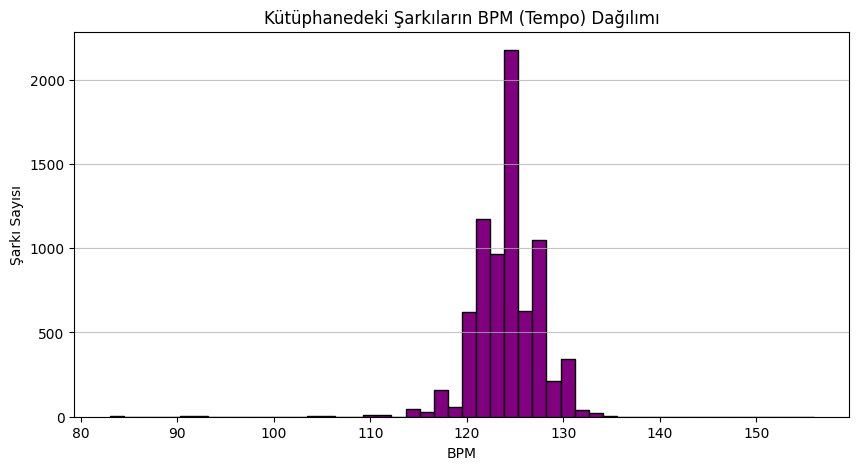

In [20]:
# ==========================================
# KEŞİFSEL VERİ ANALİZİ (EDA)
# ==========================================

# 16. Kütüphanemizdeki şarkıların BPM (tempo) dağılımını görselleştirmek için histogram grafiği çiziyoruz.
# Arşivimizin müzikal olarak hangi tempo aralıklarında (örn: 124-125 BPM) yoğunlaştığını analiz etmek içindir.
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.hist(df_temiz['mik_bpm'], bins=50, color='purple', edgecolor='black')
plt.title('Kütüphanedeki Şarkıların BPM (Tempo) Dağılımı')
plt.xlabel('BPM')
plt.ylabel('Şarkı Sayısı')
plt.grid(axis='y', alpha=0.75)
plt.show()

print("\n" + "="*50 + "\n")

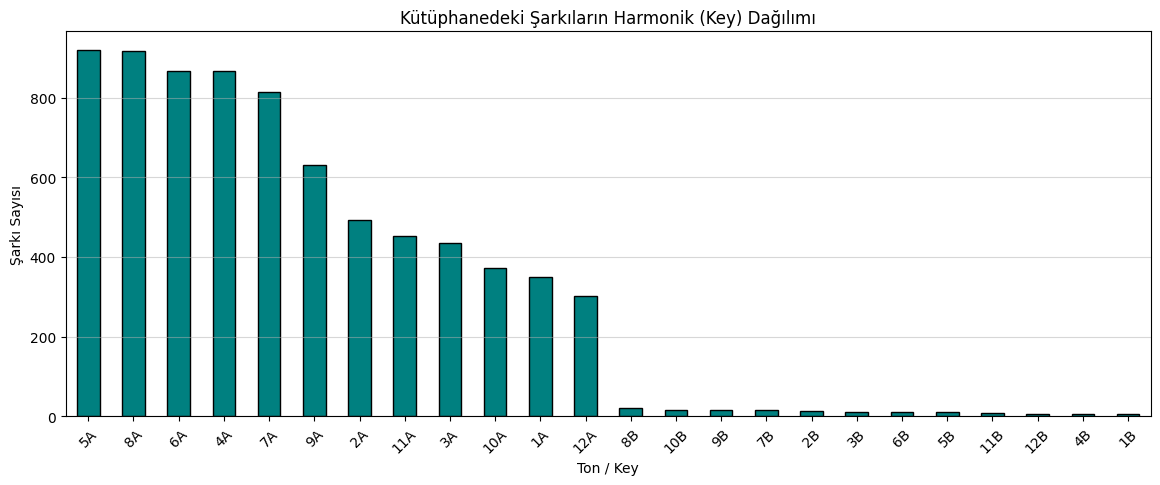

In [22]:
# 17. Arşivimizdeki şarkıların harmonik ton (Camelot Key) dağılımını çubuk grafikle görselleştiriyoruz.
# Kütüphanemizde hangi tonların daha baskın olduğunu analiz ederek arşivin genel müzikal karakteristiğini görmek içindir.

plt.figure(figsize=(14, 5))

df_temiz['mik_key_camelot'].value_counts().plot(kind='bar', color='teal', edgecolor='black')

plt.title('Kütüphanedeki Şarkıların Harmonik (Key) Dağılımı')
plt.xlabel('Ton / Key')
plt.ylabel('Şarkı Sayısı')
plt.xticks(rotation=45) # Etiketler yan yana sıkışmasın diye 45 derece eğiyoruz
plt.grid(axis='y', alpha=0.5)
plt.show()

In [23]:
# ==========================================
# MODEL KURULUMU VE EĞİTİM (TRAINING)
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# 1. Hedef Değişken (y): Modelin tahmin etmeye çalışacağı ana değer (Camelot Key / Harmonik Ton).
y = df_temiz['mik_key_camelot']

# 2. Veri Sızıntısını (Data Leakage) Önleme: Modelin "kopya çekmesini" engellemek için filtreleme yapıyoruz.
# Hedefle aynı sonucu veren diğer ton sütunlarını ve hesaplamaya girmemesi gereken kimlikleri (Sanatçı vb.) model girdisinden (X) ayırıyoruz.
kopya_ve_metin_sutunlari = [
    'mik_key_camelot', 'mik_key', 'harmoniq_key_camelot', 'harmoniq_key',
    'track_id', 'artist', 'title', 'source', 'key_agreement', 'genre', 'genre_source', 'harmoniq_confidence', 'harmoniq_second_key_camelot'
]

# Sadece tablomuzda var olanları seçip düşürüyoruz (X: Sadece modelin öğreneceği frekans ve tempo özellikleri)
dusecekler = [col for col in kopya_ve_metin_sutunlari if col in df_temiz.columns]
X = df_temiz.drop(dusecekler, axis=1)

# Garanti olsun diye sadece sayısal sütunları (BPM ve Chroma) X'te bırakıyoruz
X = X.select_dtypes(include=['number'])

# 3. Modelin ezberlemesini (overfitting) önlemek için veriyi %80 Eğitim, %20 Test olarak bölüyoruz.
# random_state=42 parametresi, denemelerin her seferinde aynı %20'lik bölümle test edilmesini (tutarlılığı) sağlar.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Eğitim Verisi Boyutu (Modelin çalışacağı):", X_train.shape)
print("Test Verisi Boyutu (Kendini sınayacağı):", X_test.shape)

# 4. Frekans verilerini matematiksel olarak net bölebilen Karar Ağacı (Decision Tree) algoritmasını oluşturup eğitiyoruz.
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

print("\nModel eğitimi başarıyla tamamlandı!")

Eğitim Verisi Boyutu (Modelin çalışacağı): (6054, 73)
Test Verisi Boyutu (Kendini sınayacağı): (1514, 73)

Model eğitimi başarıyla tamamlandı!


In [24]:
# ==========================================
# TAHMİN VE PERFORMANS DEĞERLENDİRMESİ
# ==========================================
from sklearn.metrics import accuracy_score
import pandas as pd

# 1. Modelin eğitimde hiç görmediği test verisi (X_test) üzerinde tahmin yapmasını (predict) sağlıyoruz.
y_tahmin = model.predict(X_test)

# 2. Modelin tahmin yeteneğini genel doğruluk skoru (accuracy) ile matematiksel olarak ölçüyoruz.
basari_puani = accuracy_score(y_test, y_tahmin)

print(f"Modelin Ton (Key) Tahmin Etme Başarısı: % {basari_puani * 100:.2f}")

# 3. Modelin performansını (doğrularını ve müzikal sapmalarını) somut olarak analiz etmek için
# ilk 15 şarkılık bir karşılaştırma tablosu (DataFrame) oluşturuyoruz.
karsilastirma = pd.DataFrame({
    'Gerçek Ton (y_test)': y_test.values[:15],
    'Modelin Tahmini': y_tahmin[:15]
})

print("\nİlk 15 Test Şarkısı İçin Sonuçlar:")
print(karsilastirma)

Modelin Ton (Key) Tahmin Etme Başarısı: % 79.79

İlk 15 Test Şarkısı İçin Sonuçlar:
   Gerçek Ton (y_test) Modelin Tahmini
0                  12A             12A
1                   6A              6A
2                   9A              9A
3                   5A              5A
4                   6A              6A
5                   4A              4A
6                   9A              9A
7                   6A              6A
8                   9A              9A
9                  10A             10A
10                 10A             10A
11                  7A              7A
12                 11A             11A
13                  7A              7A
14                  5A              6A


In [25]:
from IPython.display import display

# ==========================================
# FİNAL ÜRÜNÜ (DJ ASİSTANI YAZILIMI)
# ==========================================

def dj_asistani_oner_gelismis(hedef_bpm, hedef_key, tolerans=3, onerilecek_sayi=5):
    print(f"🎧 Arama Kriterleri: {hedef_bpm} BPM (Öncelikli) ve {hedef_key} Tonu\n")
    print("-" * 60)

    # 1. Veri setini hedef ton (Key) ve belirlenen BPM tolerans aralığına göre filtreliyoruz.
    uygun_ton = df_temiz[df_temiz['mik_key_camelot'] == hedef_key].copy()

    uygun_sarkilar = uygun_ton[
        (uygun_ton['mik_bpm'] >= hedef_bpm - tolerans) &
        (uygun_ton['mik_bpm'] <= hedef_bpm + tolerans)
    ].copy()

    if uygun_sarkilar.empty:
        print("Maalesef kütüphanede bu kriterlere uygun parça bulunamadı.")
        return

    # 2. Kusursuz bir mix için şarkıları hedef BPM'e yakınlıklarına (mutlak fark) göre sıralıyoruz.
    uygun_sarkilar['bpm_farki'] = abs(uygun_sarkilar['mik_bpm'] - hedef_bpm)
    uygun_sarkilar = uygun_sarkilar.sample(frac=1).sort_values(by='bpm_farki')

    # 3. Sıralanmış listeden istenen adet (örn: 5) kadar parçayı seçiyoruz.
    kac_sarki = min(onerilecek_sayi, len(uygun_sarkilar))
    oneriler = uygun_sarkilar.head(kac_sarki)

    # 4. Sunumda kafa karıştırmaması için sadece gerekli şarkı künye bilgilerini alıyoruz.
    gosterilecek = oneriler[['artist', 'title', 'mik_bpm', 'mik_key_camelot']]

    # 5. Sütun isimlerini son kullanıcının (DJ) rahat okuyabileceği profesyonel formata çeviriyoruz.
    gosterilecek = gosterilecek.rename(columns={
        'artist': 'Sanatçı',
        'title': 'Şarkı Adı',
        'mik_bpm': 'BPM',
        'mik_key_camelot': 'Harmonik Ton'
    })

    # 6. Görsel Optimizasyon: İndeksleri gizleyip BPM'i virgülden sonra 2 basamak (.00) olarak sınırlandırarak şık bir çıktı alıyoruz.
    display(gosterilecek.style.hide(axis="index").format({"BPM": "{:.2f}"}))

# Geliştirdiğimiz DJ asistanı fonksiyonunu canlı bir senaryoyla (129 BPM, 4A) test ediyoruz!
dj_asistani_oner_gelismis(hedef_bpm=129, hedef_key='4A', tolerans=3, onerilecek_sayi=5)

🎧 Arama Kriterleri: 129 BPM (Öncelikli) ve 4A Tonu

------------------------------------------------------------


Sanatçı,Şarkı Adı,BPM,Harmonik Ton
Mason Collective,Mint Condition,129.00,4A
Emery Bex,Till Daylight,129.00,4A
Danny Leblack,Para Tudo,129.00,4A
Supernova,Got Some Lovin',129.00,4A
Ms Pika,Gozadera,129.00,4A


In [27]:
from IPython.display import display

# ==========================================
# CANLI İNTERAKTİF DJ ASİSTANI (UI/UX)
# ==========================================

def interaktif_dj_asistani():
    print("🎧 Smart Mashup Assistant - DJ Modülü Aktif 🎧")
    print("=" * 50)

    # 1. Uygulamanın her aramadan sonra kapanmaması için sürekli çalışan bir döngü başlatıyoruz.
    while True:
        # 2. Kullanıcı hatalarının (sayı yerine harf girilmesi vb.) programı çökertmesini önlemek için try-except bloğu (hata yönetimi) kullanıyoruz.
        try:
            girilen_bpm = float(input("Hedef BPM değerini girin (Örn: 124): "))
            girilen_key = input("Hedef Ton/Key değerini girin (Örn: 8A, 5A): ").strip().upper()
        except ValueError:
            print("⚠️ Lütfen BPM için geçerli bir sayı (örn: 124 veya 124.5) girin!")
            print("-" * 50)
            continue # Hata alırsak döngüyü kırmaz, tekrar en baştan BPM sorar

        print(f"\n🔍 Aranıyor... {girilen_bpm} BPM ve {girilen_key} tonuna en uygun parçalar filtreleniyor...\n")

        # 3. Hedef ton (Key) ve belirlenen esneklik (±3 BPM) toleransına göre arşivimizi filtreden geçiriyoruz.
        uygun_ton = df_temiz[df_temiz['mik_key_camelot'] == girilen_key].copy()

        tolerans = 3
        uygun_sarkilar = uygun_ton[
            (uygun_ton['mik_bpm'] >= girilen_bpm - tolerans) &
            (uygun_ton['mik_bpm'] <= girilen_bpm + tolerans)
        ].copy()

        if uygun_sarkilar.empty:
            print(f"❌ Maalesef kütüphanede {girilen_bpm} BPM civarında ve {girilen_key} tonunda parça bulunamadı.")
        else:
            # 4. Mix sırasında tempoyu en az bozacak (BPM farkı en düşük) parçaları bulmak için matematiksel sıralama yapıyoruz.
            uygun_sarkilar['bpm_farki'] = abs(uygun_sarkilar['mik_bpm'] - girilen_bpm)
            uygun_sarkilar = uygun_sarkilar.sample(frac=1).sort_values(by='bpm_farki')

            # 5. Tablonun estetik ve okunabilir olması için sadece gerekli sütunları seçip Türkçeleştiriyoruz.
            oneriler = uygun_sarkilar.head(5)
            gosterilecek = oneriler[['artist', 'title', 'mik_bpm', 'mik_key_camelot']].copy()

            gosterilecek = gosterilecek.rename(columns={
                'artist': 'Sanatçı',
                'title': 'Şarkı Adı',
                'mik_bpm': 'BPM',
                'mik_key_camelot': 'Harmonik Ton'
            })

            # 6. İndeks numaralarını gizleyip, BPM'i 2 ondalık basamak formatında, şık bir tablo olarak ekrana basıyoruz.
            display(gosterilecek.style.hide(axis="index").format({"BPM": "{:.2f}"}))

        # 7. Kullanıcıya işlemi sonlandırma veya yeni bir arama yapma (döngüyü kırma/devam ettirme) opsiyonu sunuyoruz.
        print("-" * 50)
        devam_mi = input("🔄 Başka bir arama yapmak ister misin? (Evet için 'e', Çıkmak için 'h' tuşla): ").strip().lower()

        if devam_mi == 'h' or devam_mi == 'hayır':
            print("\n👋 DJ Asistanı kapatılıyor. Sahnede başarılar!")
            break # Döngüyü tamamen kırar ve programı bitirir
        else:
            print("\n" + "=" * 50 + "\n") # Yeni arama için ekranı çizgilerle ayırır

# İnteraktif Uygulamayı Başlat!
interaktif_dj_asistani()

🎧 Smart Mashup Assistant - DJ Modülü Aktif 🎧
Hedef BPM değerini girin (Örn: 124): 135
Hedef Ton/Key değerini girin (Örn: 8A, 5A): 8A

🔍 Aranıyor... 135.0 BPM ve 8A tonuna en uygun parçalar filtreleniyor...



Sanatçı,Şarkı Adı,BPM,Harmonik Ton
"The Trip, Papa Nugs",Keep Rocking,132.00,8A
"Cevin Fisher, DJ Chus",Everytime I Try,132.00,8A
Damelo,Just Do It,132.00,8A


--------------------------------------------------
🔄 Başka bir arama yapmak ister misin? (Evet için 'e', Çıkmak için 'h' tuşla): e


Hedef BPM değerini girin (Örn: 124): 85
Hedef Ton/Key değerini girin (Örn: 8A, 5A): 4A

🔍 Aranıyor... 85.0 BPM ve 4A tonuna en uygun parçalar filtreleniyor...

❌ Maalesef kütüphanede 85.0 BPM civarında ve 4A tonunda parça bulunamadı.
--------------------------------------------------
🔄 Başka bir arama yapmak ister misin? (Evet için 'e', Çıkmak için 'h' tuşla): h

👋 DJ Asistanı kapatılıyor. Sahnede başarılar!
